# 02 · TGAT-BoostNet classifier metrics
**Course 21CSC314P (SRMIST) · Distributed Streaming Anomaly Detection on Blockchain Transaction Graphs**

Full classifier report for **TGAT-BoostNet**: 4-head GATConv → 32-d embedding, concatenated with the
165 Elliptic features (197-d), classified by a cost-weighted GBDT (`w_illicit = 4.32`).

| | |
|---|---|
| Protocol | standard temporal split (Weber et al. 2019): **train = labelled steps 1–34, test = labelled steps 35–49**; illicit = positive class |
| Selection | none on test: every setting fixed a priori, decision threshold 0.5 |
| Leakage control | GBDT training rows get **cross-fitted** GAT embeddings (5 step blocks) |
| Seeds | 42, 123, 456, 789, 2024 (mean ± std; 95 % bootstrap CI of the 5-seed mean) |
| Runtime | ~2 min with the cached runs in `results/`; ~25 min on a Colab T4 / ~2 h on CPU from scratch (`USE_CACHED_RESULTS = False`) |

Every number below is computed by code in this notebook or by `src/evaluation/` functions it calls.

## 0. Setup (Colab or local)
This cell clones the repository when run in Colab (fresh runtime), installs the dependencies, makes `src/`
importable, fixes seeds and detects a GPU. Locally it only locates the repository root.

**Data.** The Elliptic CSVs are looked up in `data/raw/elliptic`, `/content/elliptic` and Google Drive
(`MyDrive/elliptic`). If they are missing, the loader tries the Kaggle API (upload `kaggle.json` first:
`!mkdir -p ~/.kaggle && cp kaggle.json ~/.kaggle/ && chmod 600 ~/.kaggle/kaggle.json`; dataset
`ellipticco/elliptic-data-set`), then falls back to a public mirror of the same three files.

In [1]:
import os, sys, subprocess, random, time, json, warnings
warnings.filterwarnings("ignore")
IN_COLAB = "google.colab" in sys.modules
REPO_URL = "https://github.com/Rayaanarora/blockchain-streaming-anomaly-detection.git"
REPO_BRANCH = "eval-notebooks"   # change to "main" once merged
MOUNT_DRIVE = False          # set True to read the CSVs from Google Drive (MyDrive/elliptic)
USE_CACHED_RESULTS = True    # True: reuse results/ shipped with the repo; False: retrain everything
QUICK = os.environ.get("BSAD_QUICK") == "1"   # smoke-test mode (tiny epochs, separate cache)

if IN_COLAB:
    ROOT = "/content/blockchain-streaming-anomaly-detection"
    if not os.path.exists(ROOT):
        subprocess.run(["git", "clone", "--depth", "1", "--branch", REPO_BRANCH, REPO_URL, ROOT], check=True)
    os.chdir(ROOT)
    import torch
    pkgs = ["torch_geometric", "xgboost>=2", "lightgbm", "catboost", "umap-learn", "seaborn", "plotly",
            "pyspark==3.5.0", "psutil", "kaggle"]
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *pkgs], check=True)
    if MOUNT_DRIVE:
        from google.colab import drive
        drive.mount("/content/drive")
else:
    ROOT = os.path.abspath(os.getcwd())
    while not os.path.exists(os.path.join(ROOT, "src", "evaluation")) and os.path.dirname(ROOT) != ROOT:
        ROOT = os.path.dirname(ROOT)
    os.chdir(ROOT)
sys.path.insert(0, ROOT)
if not USE_CACHED_RESULTS:   # recompute into a fresh cache (notebook 03 reuses what notebook 02 computed)
    os.environ["BSAD_RESULTS_DIR"] = os.path.join(ROOT, "results_fresh")
if QUICK:
    os.environ["BSAD_RESULTS_DIR"] = os.path.join(ROOT, "results_quick")
    os.environ["BSAD_FIG_DIR"] = os.path.join(ROOT, "results_quick", "figures")
    os.environ["BSAD_TAB_DIR"] = os.path.join(ROOT, "results_quick", "tables")

import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
from src.evaluation.tgat_boostnet import get_device
DEVICE = get_device()
print(f"repo={ROOT}  colab={IN_COLAB}  device={DEVICE}  torch={torch.__version__}  quick={QUICK}")
if DEVICE == "cuda":
    print(torch.cuda.get_device_name(0))
from src.evaluation import plotting as PL
PL.set_style()
pd.set_option("display.width", 200, "display.max_columns", 40, "display.precision", 4)

repo=D:\blockchainbigdata\blockchain-streaming-anomaly-detection  colab=False  device=cpu  torch=2.14.1+cpu  quick=False


## 1. Data and split

In [2]:
from src.evaluation.data import load_elliptic, SEEDS, cross_step_edges, standardise
from src.evaluation import baselines as B
from src.evaluation.metrics import full_metrics, METRIC_LABELS, bootstrap_metrics_table, per_timestep
data = load_elliptic()
tr, te = data.train_mask, data.test_mask
y_te, steps_te = data.y[te], data.time_steps[te]
split = pd.DataFrame({
    "steps": ["1-34", "35-49"],
    "labelled tx": [tr.sum(), te.sum()],
    "illicit": [(data.y[tr] == 1).sum(), (y_te == 1).sum()],
    "licit": [(data.y[tr] == 0).sum(), (y_te == 0).sum()],
}, index=["train", "test"])
split["illicit %"] = 100 * split.illicit / split["labelled tx"]
split["licit:illicit"] = split.licit / split.illicit
print("nodes", data.n, "edges", data.edge_index.shape[1], "cross-time-step edges", cross_step_edges(data))
display(split)
N_BOOT = 200 if QUICK else 1000
OURS = B.OURS
LAB = {k: v[0] for k, v in B.MODELS.items()}

Elliptic CSVs found in D:\blockchainbigdata\blockchain-streaming-anomaly-detection\data\raw\elliptic


nodes 203769 edges 234355 cross-time-step edges 0


,steps,labelled tx,illicit,licit,illicit %,licit:illicit
train,1-34,29894,3462,26432,11.5809,7.6349
test,35-49,16670,1083,15587,6.4967,14.3924


## 2. Train (or load) TGAT-BoostNet for 5 seeds
`B.run` returns the cached run if `results/runs/tgat_boostnet/seed_<s>` exists, otherwise trains it
(6 GAT fits per seed: one on all of steps 1–34 for test embeddings + 5 cross-fitting folds).

In [3]:
runs = {s: B.run(OURS, data, s, DEVICE) for s in SEEDS}
P = [runs[s]["p_test"] for s in SEEDS]
print(json.dumps(runs[SEEDS[0]]["config"], indent=1))

{
 "heads": 4,
 "hidden": 32,
 "emb_dim": 32,
 "dropout": 0.3,
 "lr": 0.005,
 "weight_decay": 0.0005,
 "epochs": 100,
 "gnn_class_weight": [
  0.3,
  0.7
 ],
 "n_folds": 5,
 "w_illicit": 4.32,
 "use_gat": true,
 "temporal": false,
 "standardise_gat_input": true,
 "gbdt": {
  "n_estimators": 300,
  "max_depth": 6,
  "learning_rate": 0.05,
  "subsample": 0.8,
  "colsample_bytree": 0.8,
  "min_child_weight": 1,
  "reg_lambda": 1.0
 }
}


## 3. Metrics with 95 % bootstrap confidence intervals
Threshold 0.5. CI = percentile interval of the **5-seed mean** over 1,000 resamples of the 16,670 test
transactions (each resample is scored for all five seeds and averaged).

In [4]:
tab = bootstrap_metrics_table(y_te, P, n_boot=N_BOOT)
tab.index = [METRIC_LABELS[k] for k in tab.index]
tab["mean ± std (5 seeds)"] = [f"{m:.4f} ± {s:.4f}" for m, s in zip(tab["mean"], tab["std"])]
tab["95% CI"] = [f"[{a:.4f}, {b:.4f}]" for a, b in zip(tab.ci_low, tab.ci_high)]
per_seed = pd.DataFrame({s: full_metrics(y_te, runs[s]["p_test"]) for s in SEEDS}).T
PL.save_table(tab[["mean", "std", "ci_low", "ci_high"]], "02_tgat_boostnet_metrics",
              "TGAT-BoostNet, test steps 35-49 (threshold 0.5): mean, std over 5 seeds, 95% bootstrap CI", float_fmt="{:.4f}")
PL.save_table(per_seed, "02_tgat_boostnet_metrics_per_seed", "TGAT-BoostNet metrics per seed", float_fmt="{:.4f}")
display(tab[["mean ± std (5 seeds)", "95% CI"]])

,mean ± std (5 seeds),95% CI
Accuracy,0.9764 ± 0.0017,"[0.9743, 0.9786]"
Balanced acc.,0.8399 ± 0.0025,"[0.8261, 0.8530]"
Precision (illicit),0.9387 ± 0.0382,"[0.9266, 0.9515]"
Recall (illicit),0.6829 ± 0.0064,"[0.6552, 0.7092]"
F1 (illicit),0.7903 ± 0.0111,"[0.7706, 0.8090]"
F0.5 (illicit),0.8729 ± 0.0252,"[0.8595, 0.8856]"
F2 (illicit),0.7221 ± 0.0039,"[0.6969, 0.7459]"
Specificity,0.9968 ± 0.0022,"[0.9962, 0.9975]"
FPR,0.0032 ± 0.0022,"[0.0025, 0.0038]"
FNR,0.3171 ± 0.0064,"[0.2908, 0.3448]"


### 3b. The course's classification metrics
Accuracy, Precision, Recall, F1, Specificity, AUC-ROC, Log Loss, MCC, Cohen's Kappa and Balanced Accuracy
(illicit = positive class; Precision / Recall / F1 are for the illicit class). Dots = 5-seed mean, bars = 95 %
bootstrap CI. Accuracy and specificity are dominated by the 93.5 % licit majority, so MCC, Kappa, Balanced
Accuracy and the illicit-class scores are the informative ones on this imbalanced data.

,mean,std,ci_low,ci_high
Accuracy,0.9764,0.0017,0.9743,0.9786
Precision (illicit),0.9387,0.0382,0.9266,0.9515
Recall (illicit),0.6829,0.0064,0.6552,0.7092
F1 (illicit),0.7903,0.0111,0.7706,0.8090
Specificity,0.9968,0.0022,0.9962,0.9975
ROC-AUC,0.9315,0.0053,0.9231,0.9394
Log-loss,0.1218,0.0036,0.1094,0.1344
MCC,0.7894,0.0152,0.7705,0.8069
Cohen's kappa,0.7781,0.0121,0.7577,0.7979
Balanced acc.,0.8399,0.0025,0.8261,0.8530


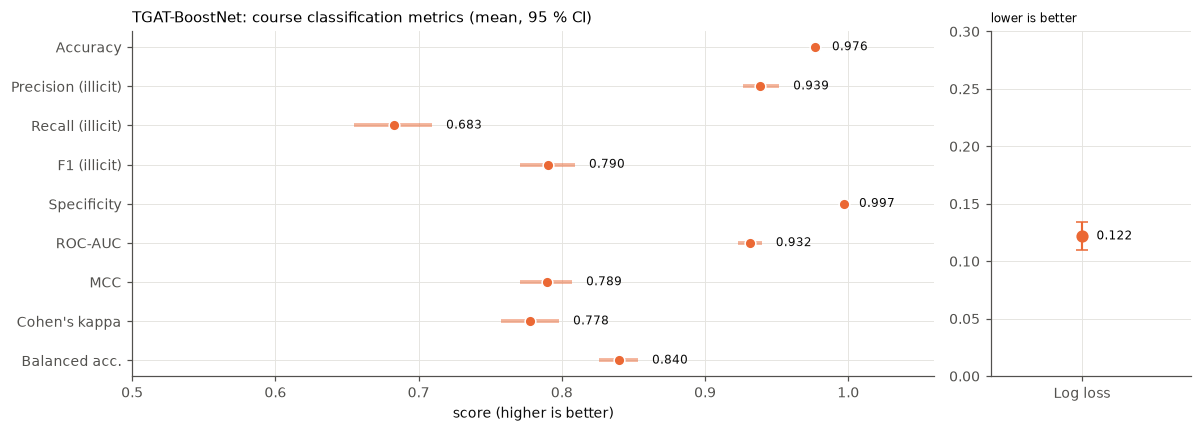

In [5]:
TEACHER_CLS = ["accuracy", "precision", "recall", "f1", "specificity", "roc_auc", "log_loss", "mcc", "kappa",
               "balanced_accuracy"]
tt = tab.copy(); tt.index = list(METRIC_LABELS)          # back to metric keys
course = tt.loc[TEACHER_CLS, ["mean", "std", "ci_low", "ci_high"]]
course.index = [METRIC_LABELS[k] for k in TEACHER_CLS]
PL.save_table(course, "02_course_metrics", "TGAT-BoostNet: course classification metrics (test 35-49, 5 seeds, 95% CI)",
              float_fmt="{:.4f}")
display(course)
fig, axes = plt.subplots(1, 2, figsize=(11, 4), gridspec_kw={"width_ratios": [4, 1]})
unit = [k for k in TEACHER_CLS if k != "log_loss"]
c = tt.loc[unit]
ypos = np.arange(len(unit))[::-1]
axes[0].hlines(ypos, c.ci_low, c.ci_high, color=PL.OURS_COLOR, lw=2.5, alpha=0.5)
axes[0].plot(c["mean"], ypos, "o", color=PL.OURS_COLOR, ms=7, mec="white", mew=1)
for y_, (k, r) in zip(ypos, c.iterrows()):
    axes[0].text(r.ci_high + 0.01, y_, f"{r['mean']:.3f}", va="center", fontsize=8, color=PL.INK)
axes[0].set_yticks(ypos); axes[0].set_yticklabels([METRIC_LABELS[k] for k in unit])
axes[0].set_xlim(min(0.5, c.ci_low.min() - 0.05), 1.06); axes[0].set_xlabel("score (higher is better)")
axes[0].set_title("TGAT-BoostNet: course classification metrics (mean, 95 % CI)", loc="left")
ll = tt.loc["log_loss"]
axes[1].errorbar([0], [ll["mean"]], yerr=[[ll["mean"] - ll.ci_low], [ll.ci_high - ll["mean"]]], fmt="o",
                 color=PL.OURS_COLOR, capsize=4, ms=7)
axes[1].text(0.08, ll["mean"], f"{ll['mean']:.3f}", va="center", fontsize=8)
axes[1].set_xticks([0]); axes[1].set_xticklabels(["Log loss"]); axes[1].set_xlim(-0.5, 0.6)
axes[1].set_ylim(0, max(0.3, ll.ci_high * 1.3)); axes[1].set_title("lower is better", loc="left", fontsize=8)
fig.tight_layout(); PL.savefig(fig, "02_course_metrics"); plt.show()

## 4. Confusion matrices (row-normalised), one per seed

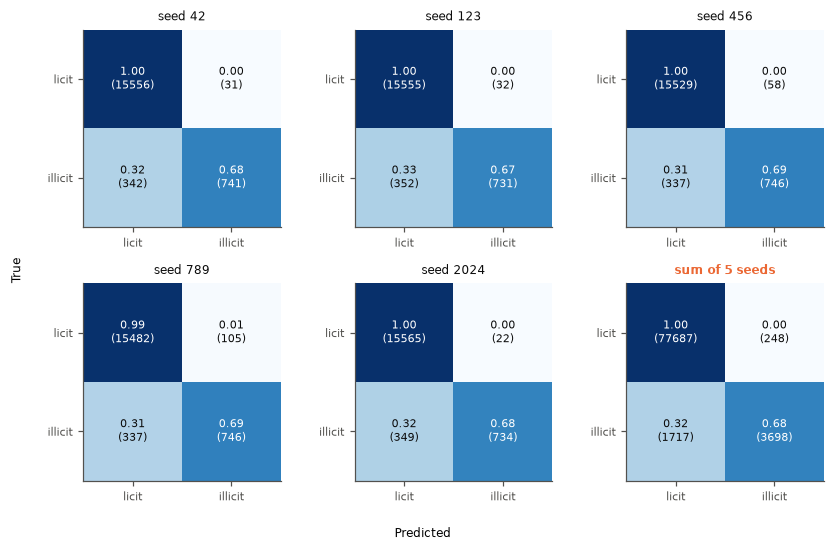

In [6]:
cms = {}
for s in SEEDS:
    m = full_metrics(y_te, runs[s]["p_test"])
    cms[f"seed {s}"] = np.array([[m["tn"], m["fp"]], [m["fn"], m["tp"]]])
cms["sum of 5 seeds"] = sum(cms.values())
fig = PL.confusion_grid(cms, {k: k for k in cms}, ours="sum of 5 seeds", ncols=3)
PL.savefig(fig, "02_confusion_matrices"); plt.show()

## 5. Per-time-step F1 and recall (test steps 35–49)
The dark-market shutdown at step 43 (Weber et al. 2019) is marked. Bands = min–max over seeds.

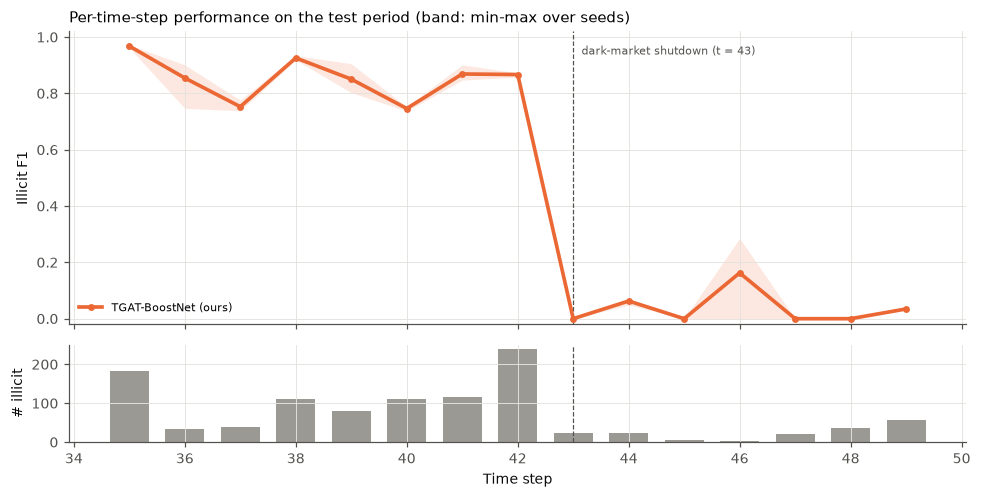

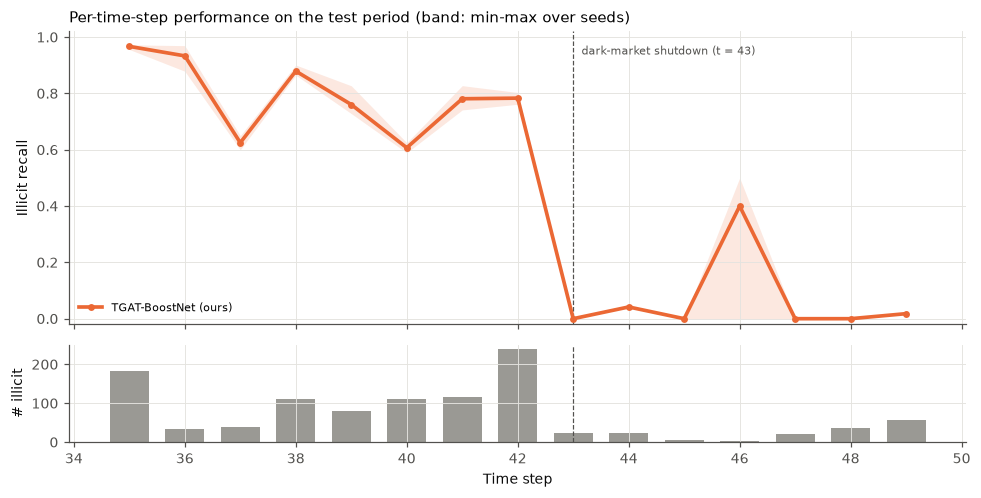

steps 35-42         steps 43-49        
                 mean     std        mean     std
precision      0.9619  0.0222      0.1582  0.0663
recall         0.8061  0.0073      0.0166  0.0026
f1             0.8770  0.0067      0.0292  0.0043

In [7]:
rows = []
for s in SEEDS:
    for r in per_timestep(y_te, runs[s]["p_test"], steps_te):
        rows.append(dict(r, model=OURS, seed=s))
pts = pd.DataFrame(rows)
counts = pts[pts.seed == SEEDS[0]].set_index("time_step").n_illicit
for metric in ("f1", "recall"):
    fig = PL.per_timestep_lines(pts, OURS, [], LAB, metric=metric, counts=counts)
    PL.savefig(fig, f"02_per_timestep_{metric}"); plt.show()
pt_tab = pts.groupby("time_step")[["precision", "recall", "f1"]].agg(["mean", "std"])
pt_tab.columns = [f"{a}_{b}" for a, b in pt_tab.columns]
pt_tab.insert(0, "n_illicit", counts)
PL.save_table(pt_tab, "02_per_timestep", "TGAT-BoostNet per test time step (mean, std over 5 seeds)")
pre, post = pts[pts.time_step < 43], pts[pts.time_step >= 43]
def pooled(df_seed_rows, lo, hi):
    out = []
    for s in SEEDS:
        m = (steps_te >= lo) & (steps_te <= hi)
        out.append(full_metrics(y_te[m], runs[s]["p_test"][m]))
    return pd.DataFrame(out)[["precision", "recall", "f1"]].agg(["mean", "std"]).T
split43 = pd.concat({"steps 35-42": pooled(None, 35, 42), "steps 43-49": pooled(None, 43, 49)}, axis=1)
display(split43)
PL.save_table(split43, "02_before_after_step43", "TGAT-BoostNet before vs after the step-43 shutdown")

## 6. ROC / PR curves, calibration and threshold sweep

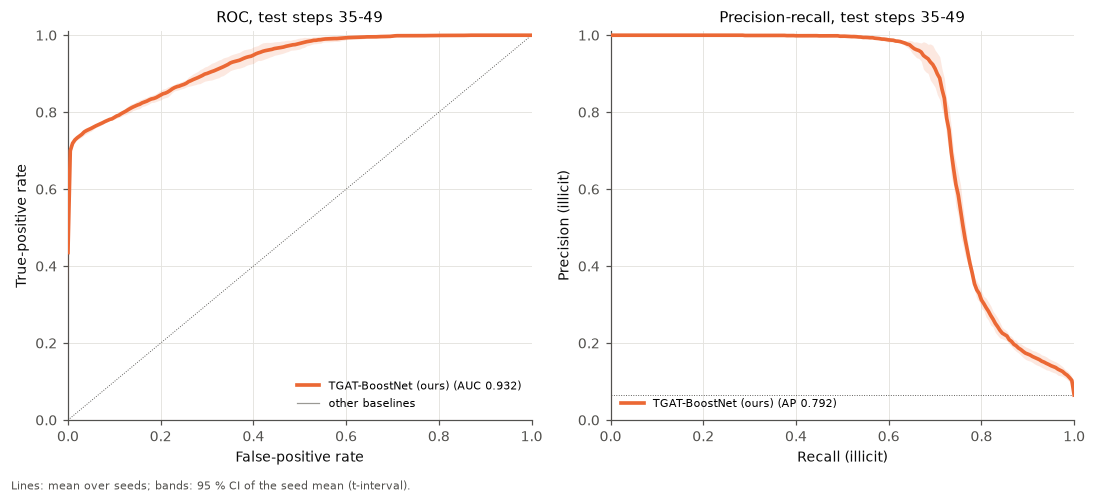

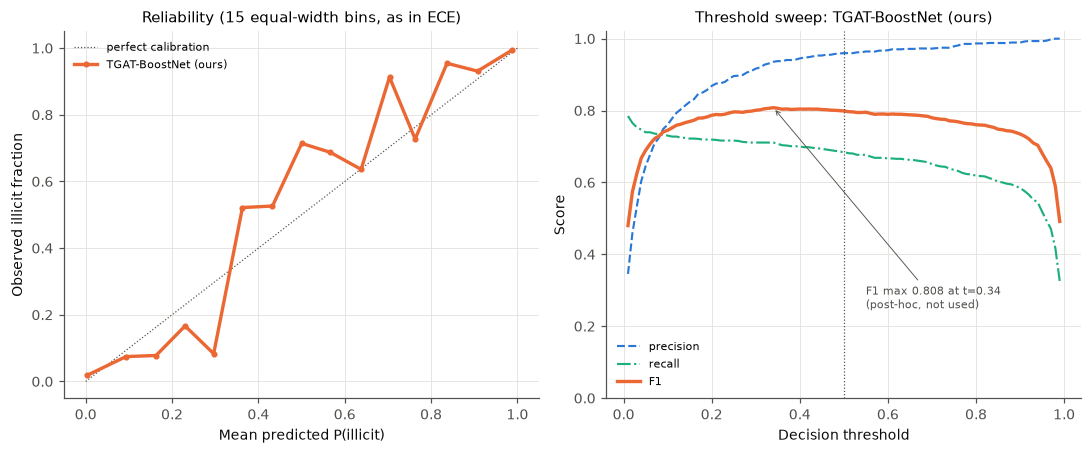

In [8]:
fig = PL.roc_pr_overlay(y_te, {OURS: P}, LAB, OURS)
PL.savefig(fig, "02_roc_pr"); plt.show()
fig = PL.calibration_and_threshold(y_te, {OURS: P[0]}, LAB, OURS)
PL.savefig(fig, "02_calibration_threshold"); plt.show()

## 7. Efficiency: training time, inference latency, throughput, size
A *micro-batch* is one complete Elliptic time-step snapshot (all its transactions, labelled or not) — the
unit the streaming scorer receives. Latency = median / p95 wall time to score one snapshot (GAT forward on
the snapshot + GBDT), measured over the 15 test snapshots after one warm-up.

Timing caveat: the 5-seed runs were trained by parallel worker processes sharing one CPU, so their
training times are inflated. If `results/timing/` exists, the **idle-machine** re-run of seed 42 (same
code, nothing else running) is shown as the reference timing.

In [9]:
def timing_run(key, seed=42):
    p = os.path.join(B.RESULTS_DIR, "timing", "runs", key, f"seed_{seed}.json")
    return json.load(open(p)) if os.path.exists(p) else None
eff = pd.DataFrame({s: {k: runs[s].get(k) for k in ("train_seconds", "gat_full_seconds", "crossfit_seconds",
                                                    "gbdt_seconds", "latency_ms_median", "latency_ms_p95",
                                                    "throughput_tx_per_s", "n_params", "gat_params", "size_bytes")}
                    for s in SEEDS}).T.astype(float)
summary = eff.agg(["mean", "std"]).T
idle = timing_run(OURS)
if idle:
    summary["idle machine (seed 42)"] = [idle.get(k) for k in summary.index]
summary["unit"] = ["s", "s", "s", "s", "ms / snapshot", "ms / snapshot", "tx / s", "GAT weights + tree nodes",
                   "GAT weights", "bytes"]
print("device:", runs[SEEDS[0]].get("device"), "| torch threads:", runs[SEEDS[0]].get("torch_threads"),
      "| platform:", runs[SEEDS[0]].get("platform"))
PL.save_table(summary, "02_efficiency", "TGAT-BoostNet efficiency", float_fmt="{:.2f}")
display(summary)

device: cpu | torch threads: 5 | platform: Windows-11-10.0.26200-SP0


,mean,std,idle machine (seed 42),unit
train_seconds,1206.9856,172.8061,495.2067,s
gat_full_seconds,217.7837,13.3783,94.1167,s
crossfit_seconds,965.6077,167.0718,396.9373,s
gbdt_seconds,21.4406,24.0036,3.6994,s
latency_ms_median,127.5521,105.9936,22.6063,ms / snapshot
latency_ms_p95,236.9057,211.1239,27.1336,ms / snapshot
throughput_tx_per_s,52377.4137,32664.4694,217198.8797,tx / s
n_params,44984.0000,216.0879,45054.0000,GAT weights + tree nodes
gat_params,25762.0000,0.0000,25762.0000,GAT weights
size_bytes,959070.2000,7348.5365,961448.0000,bytes


## 8. Training-loss and learning curves
* GAT cross-entropy per epoch (the GAT trained on all of steps 1–34, every seed).
* GBDT log-loss per boosting round on train and test (seed 42; the test curve is **monitoring only** —
  the number of rounds is fixed at 300 and was not chosen from it).
* Learning curve: test F1 / PR-AUC when the GBDT is trained on steps 1..k only (embeddings fixed).

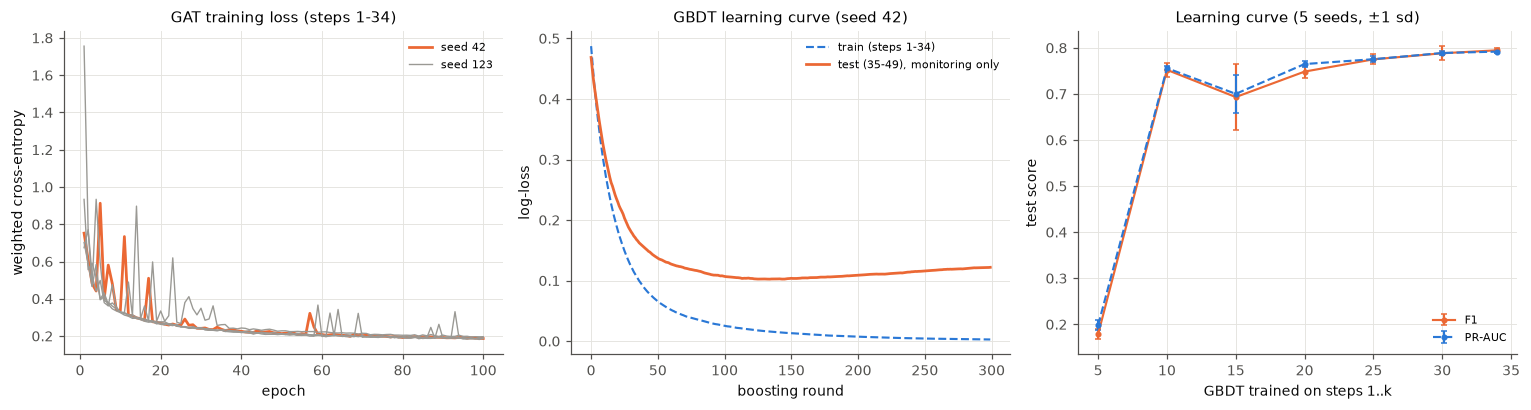

,n_train,f1,pr_auc
last_train_step,,,
5,7865.000,0.179,0.199
10,12468.000,0.752,0.756
15,15514.000,0.693,0.700
20,18889.000,0.749,0.765
25,24200.000,0.775,0.775
30,26905.000,0.788,0.789
34,29894.000,0.795,0.792


In [10]:
import xgboost as xgb
from src.evaluation.tgat_boostnet import DEFAULT_GBDT, make_xgb
Xs = standardise(data)[0]
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for i, s in enumerate(SEEDS):
    h = runs[s].get("gat_loss_history") or []
    axes[0].plot(range(1, len(h) + 1), h, color=PL.OURS_COLOR if i == 0 else PL.GREY, lw=1.8 if i == 0 else 0.9,
                 label=f"seed {s}" if i < 2 else None)
axes[0].set(xlabel="epoch", ylabel="weighted cross-entropy", title="GAT training loss (steps 1-34)")
axes[0].legend()
emb_tr, emb_te = B.load_embeddings(OURS, SEEDS[0])
F_tr, F_te = np.hstack([Xs[tr], emb_tr]), np.hstack([Xs[te], emb_te])
mon = make_xgb(DEFAULT_GBDT, 4.32, SEEDS[0], DEVICE)
mon.fit(F_tr, data.y[tr], eval_set=[(F_tr, data.y[tr]), (F_te, y_te)], verbose=False)
ev = mon.evals_result()
axes[1].plot(ev["validation_0"]["logloss"], color=PL.CATEGORICAL[0], ls="--", label="train (steps 1-34)")
axes[1].plot(ev["validation_1"]["logloss"], color=PL.OURS_COLOR, lw=1.8, label="test (35-49), monitoring only")
axes[1].set(xlabel="boosting round", ylabel="log-loss", title="GBDT learning curve (seed 42)")
axes[1].legend()
lc = []
for k in (5, 10, 15, 20, 25, 30, 34):
    m_tr = data.time_steps[tr] <= k
    for s in SEEDS:
        e_tr, e_te = B.load_embeddings(OURS, s)
        clf = make_xgb(DEFAULT_GBDT, 4.32, s, DEVICE)
        clf.fit(np.hstack([Xs[tr], e_tr])[m_tr], data.y[tr][m_tr])
        p = clf.predict_proba(np.hstack([Xs[te], e_te]))[:, 1]
        mm = full_metrics(y_te, p)
        lc.append(dict(last_train_step=k, seed=s, n_train=int(m_tr.sum()), f1=mm["f1"], pr_auc=mm["pr_auc"]))
lc = pd.DataFrame(lc)
g = lc.groupby("last_train_step")
for col, c, ls in (("f1", PL.OURS_COLOR, "-"), ("pr_auc", PL.CATEGORICAL[0], "--")):
    axes[2].errorbar(g[col].mean().index, g[col].mean(), yerr=g[col].std(), color=c, ls=ls, marker="o", ms=3,
                     capsize=2, label=col.upper().replace("_", "-"))
axes[2].set(xlabel="GBDT trained on steps 1..k", ylabel="test score", title="Learning curve (5 seeds, ±1 sd)")
axes[2].legend()
fig.tight_layout(); PL.savefig(fig, "02_training_and_learning_curves"); plt.show()
PL.save_table(g[["n_train", "f1", "pr_auc"]].mean(), "02_learning_curve", "Learning curve, mean of 5 seeds")

## 9. Representation geometry: raw features vs GAT embeddings vs fused 197-d
t-SNE (and UMAP if installed) on a stratified sample of test transactions (all illicit up to 1,000 + 3,000 licit),
seed 42 embeddings. Silhouette scores (class labels, Euclidean, on the standardised input space) quantify separation.

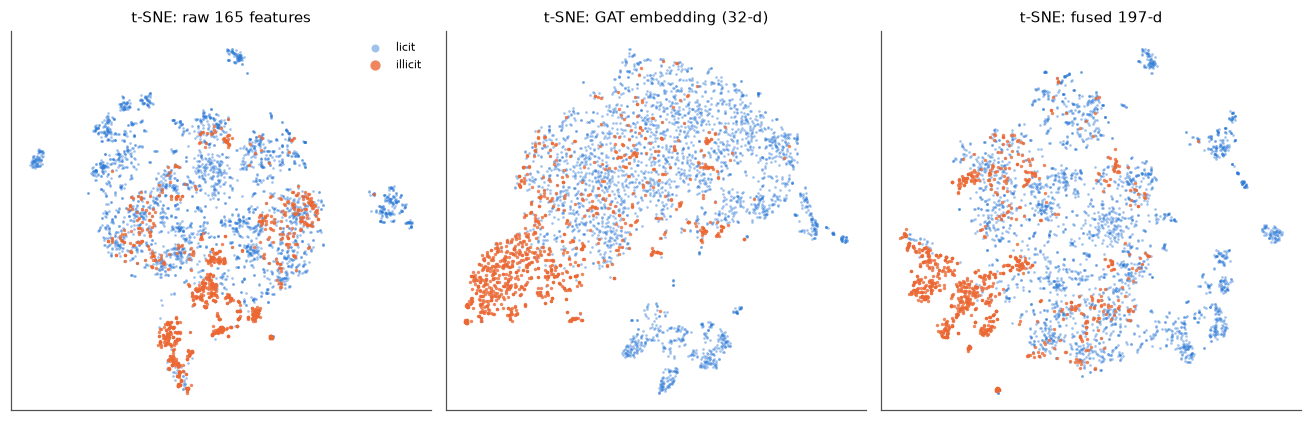

umap-learn not installed; UMAP panel skipped


,silhouette (illicit vs licit)
raw 165 features,-0.0694
GAT embedding (32-d),-0.1852
fused 197-d,-0.1086


In [11]:
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score
rng = np.random.default_rng(0)
ill, lic = np.flatnonzero(y_te == 1), np.flatnonzero(y_te == 0)
samp = np.concatenate([rng.choice(ill, min(1000, len(ill)), replace=False), rng.choice(lic, 3000, replace=False)])
spaces = {"raw 165 features": Xs[te][samp], "GAT embedding (32-d)": emb_te[samp],
          "fused 197-d": np.hstack([Xs[te][samp], (emb_te[samp] - emb_tr.mean(0)) / (emb_tr.std(0) + 1e-6)])}
panels, sil = [], {}
for name, Z in spaces.items():
    sil[name] = silhouette_score(Z, y_te[samp])
    panels.append((f"t-SNE: {name}", TSNE(2, random_state=0, init="pca", perplexity=40).fit_transform(Z)))
fig = PL.embedding_panels(panels, y_te[samp]); PL.savefig(fig, "02_tsne_raw_gat_fused"); plt.show()
try:
    import umap
    panels_u = [(f"UMAP: {n}", umap.UMAP(random_state=0).fit_transform(Z)) for n, Z in spaces.items()]
    fig = PL.embedding_panels(panels_u, y_te[samp]); PL.savefig(fig, "02_umap_raw_gat_fused"); plt.show()
except ImportError:
    print("umap-learn not installed; UMAP panel skipped")
display(pd.Series(sil, name="silhouette (illicit vs licit)").to_frame())

## 10. SHAP on the fused manifold
Exact TreeSHAP contributions from XGBoost (`pred_contribs=True`) for the seed-42 TGAT-BoostNet booster on all
test transactions. Right panel: share of mean |SHAP| carried by raw local, raw aggregated and GAT dimensions.

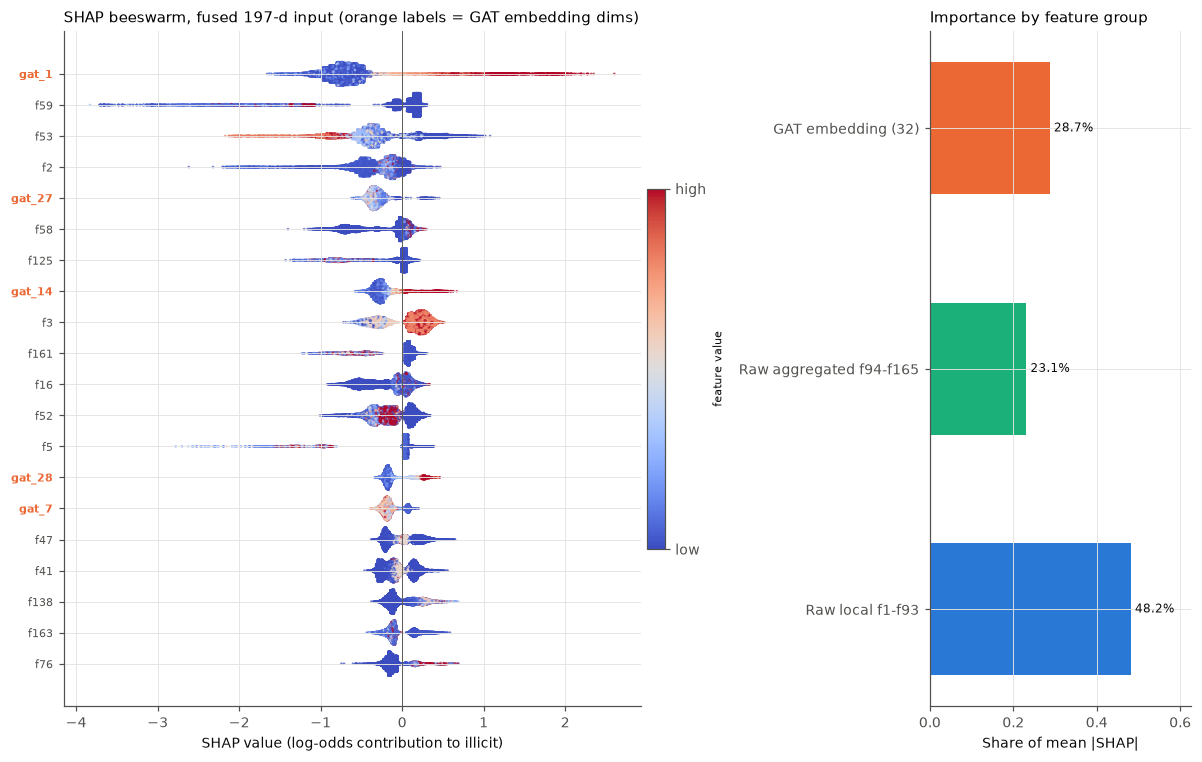

GAT dims among top-20: 5; GAT share of total |SHAP|: 28.7%


In [12]:
art = os.path.join(B.RESULTS_DIR, "artifacts", f"{OURS}_seed{SEEDS[0]}")
booster = xgb.Booster(); booster.load_model(os.path.join(art, "booster.ubj"))
contrib = booster.predict(xgb.DMatrix(F_te), pred_contribs=True)[:, :-1]
names = [f"f{i}" for i in range(1, 166)] + [f"gat_{j}" for j in range(emb_te.shape[1])]
is_gat = np.array([n.startswith("gat_") for n in names])
fig = PL.shap_beeswarm(contrib, F_te, names, is_gat, top=20); PL.savefig(fig, "02_shap_beeswarm"); plt.show()
imp = pd.Series(np.abs(contrib).mean(0), index=names).sort_values(ascending=False)
PL.save_table(imp.head(30).to_frame("mean |SHAP|"), "02_shap_top30", "Top-30 features by mean |SHAP| (seed 42)",
              float_fmt="{:.4f}")
print(f"GAT dims among top-20: {is_gat[np.argsort(-np.abs(contrib).mean(0))[:20]].sum()}; "
      f"GAT share of total |SHAP|: {np.abs(contrib)[:, is_gat].sum() / np.abs(contrib).sum():.1%}")

## 11. GAT attention on a sampled illicit subgraph
First-layer attention coefficients α_ij (mean over the 4 heads) of the seed-42 GAT on the 2-hop
neighbourhood of an illicit test transaction. Edge width ∝ attention; node colour = true class; node size ∝
TGAT-BoostNet P(illicit).

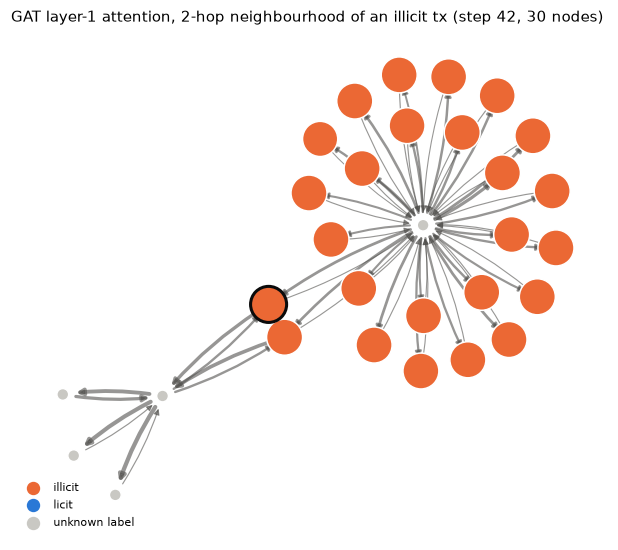

In [13]:
import networkx as nx
from src.models.graph_encoder import load_encoder
from src.evaluation.data import induced, bidirectional
gat = load_encoder(torch.load(os.path.join(art, "gat.pt"), map_location="cpu"))
E = bidirectional(data.edge_index)
step = 42
m_step = data.time_steps == step
idx, e_sub = induced(m_step, E)
with torch.no_grad():
    _, (ei_att, alpha) = gat.gat1(torch.as_tensor(Xs[idx]), torch.as_tensor(e_sub), return_attention_weights=True)
alpha = alpha.mean(1).numpy(); ei_att = ei_att.numpy()
G_all = nx.Graph(); G_all.add_edges_from(e_sub.T.tolist())
y_sub = data.y[idx]
cands = [n for n in np.flatnonzero(y_sub == 1) if n in G_all and 6 <= len(nx.single_source_shortest_path_length(G_all, n, 2)) <= 40]
if not cands:  # fall back to any illicit node with neighbours
    cands = [n for n in np.flatnonzero(y_sub == 1) if n in G_all]
center = cands[int(np.argmax([len(nx.single_source_shortest_path_length(G_all, n, 2)) for n in cands]))]
nodes = list(nx.single_source_shortest_path_length(G_all, center, 2))
H = nx.DiGraph(); H.add_nodes_from(nodes)
att = {}
for (s_, t_), a in zip(ei_att.T, alpha):
    if s_ in H and t_ in H and s_ != t_:
        att[(s_, t_)] = a
H.add_edges_from(att)
p_all = np.zeros(data.n); p_all[te] = P[0]
p_nodes = p_all[idx][nodes]
fig, ax = plt.subplots(figsize=(7, 6))
pos = nx.spring_layout(H.to_undirected(), seed=3)
col = {1: PL.OURS_COLOR, 0: PL.CATEGORICAL[0], -1: "#c9c8c3"}
nx.draw_networkx_edges(H, pos, ax=ax, width=[0.5 + 6 * att[e] for e in H.edges], edge_color=PL.INK2, alpha=0.6,
                       arrows=True, arrowsize=8, connectionstyle="arc3,rad=0.08")
nx.draw_networkx_nodes(H, pos, ax=ax, node_color=[col[int(y_sub[n])] for n in nodes],
                       node_size=[60 + 500 * p for p in p_nodes], edgecolors="white", linewidths=1)
nx.draw_networkx_nodes(H, pos, nodelist=[center], ax=ax, node_color="none", edgecolors=PL.INK, linewidths=2,
                       node_size=60 + 500 * p_all[idx][center])
for lab, c in (("illicit", PL.OURS_COLOR), ("licit", PL.CATEGORICAL[0]), ("unknown label", "#c9c8c3")):
    ax.scatter([], [], c=c, s=60, label=lab)
ax.legend(loc="lower left"); ax.set_axis_off()
ax.set_title(f"GAT layer-1 attention, 2-hop neighbourhood of an illicit tx (step {step}, {len(nodes)} nodes)", loc="left")
PL.savefig(fig, "02_gat_attention_subgraph"); plt.show()

## 12. Summary

In [14]:
t = tab["mean"]
txt = (f"**TGAT-BoostNet on test steps 35–49 (5 seeds, threshold 0.5):** illicit F1 {t['F1 (illicit)']:.3f} "
       f"(95 % CI {tab.loc['F1 (illicit)', 'ci_low']:.3f}–{tab.loc['F1 (illicit)', 'ci_high']:.3f}), precision "
       f"{t['Precision (illicit)']:.3f}, recall {t['Recall (illicit)']:.3f}, ROC-AUC {t['ROC-AUC']:.3f}, PR-AUC "
       f"{t['PR-AUC (AP)']:.3f}, MCC {t['MCC']:.3f}, ECE {t['ECE (15 bins)']:.3f}. Recall before step 43: "
       f"{split43.loc['recall', ('steps 35-42', 'mean')]:.3f}; from step 43 on: "
       f"{split43.loc['recall', ('steps 43-49', 'mean')]:.3f} — the model does not survive the step-43 regime change.")
display(Markdown(txt))
with open(os.path.join(PL.TAB_DIR, "02_summary.md"), "w", encoding="utf-8") as f:
    f.write(txt + "\n")

**TGAT-BoostNet on test steps 35–49 (5 seeds, threshold 0.5):** illicit F1 0.790 (95 % CI 0.771–0.809), precision 0.939, recall 0.683, ROC-AUC 0.932, PR-AUC 0.792, MCC 0.789, ECE 0.017. Recall before step 43: 0.806; from step 43 on: 0.017 — the model does not survive the step-43 regime change.

## 13. Download figures and tables

In [15]:
import zipfile
zp = os.path.join(ROOT, "02_classifier_metrics_outputs.zip")
with zipfile.ZipFile(zp, "w", zipfile.ZIP_DEFLATED) as zf:
    for d in (PL.FIG_DIR, PL.TAB_DIR):
        for f in sorted(os.listdir(d)):
            if f.startswith("02_"):
                zf.write(os.path.join(d, f), os.path.join(os.path.basename(d), f))
print("wrote", zp)
if IN_COLAB:
    from google.colab import files
    files.download(zp)

wrote D:\blockchainbigdata\blockchain-streaming-anomaly-detection\02_classifier_metrics_outputs.zip
